# Level 2 · Task 2 — Wine Quality Prediction
**Track:** Data Analytics · Level 2  
**Goal:** Train and compare three classifiers (Random Forest, SGD, SVC) that predict wine quality from physicochemical properties.

**Dataset:** UCI *Wine Quality* — white *Vinho Verde* wine, `winequality-white.csv` (4,898 samples, 11 features + `quality` score from 3 to 9). Source: Cortez et al. (2009), UCI Machine Learning Repository.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load Data & Inspect Structure
The file uses `;` as the separator, so `sep=";"` is required.

In [6]:
df = pd.read_csv("winequality-white.csv", sep=";")
print("Shape:", df.shape)
print("\nNull values per column:"); print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.info()
df.head()

Shape: (4898, 12)

Null values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 937
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   fl

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


### Observations
- **4,898 rows × 12 columns**, all numeric; there are **no missing values**.
- There are **937 duplicate rows (19% of the data)**. Wine samples with identical measurements and the same score are repeated, which becomes important when we split into train and test sets (see Section 5).

## 2. Distribution of the Quality Scores

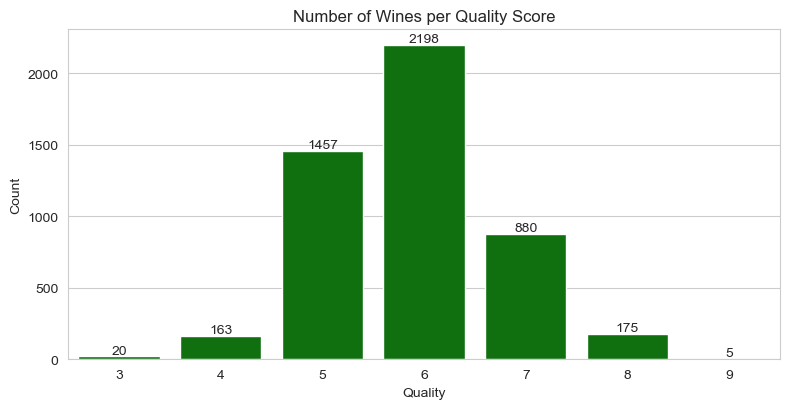

quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: count, dtype: float64


In [8]:
counts = df["quality"].value_counts().sort_index()
plt.figure(figsize=(8, 4.2))
sns.barplot(x=counts.index, y=counts.values, color="green")
for i, v in enumerate(counts.values):
    plt.text(i, v + 20, str(v), ha="center")
plt.title("Number of Wines per Quality Score"); plt.xlabel("Quality"); plt.ylabel("Count")
plt.tight_layout(); plt.show()
print((counts / counts.sum() * 100).round(2))

### Observations
- Most wines are rated **5, 6 or 7**: quality 6 has 2,198 wines (45%), quality 5 has 1,457 and quality 7 has 880.
- The extremes are very rare: only **20 wines at quality 3** and **5 at quality 9**, and just 163 at quality 4 and 175 at quality 8.
- The distribution is roughly bell-shaped and centred on 6.

## 3. Exploratory Data Analysis

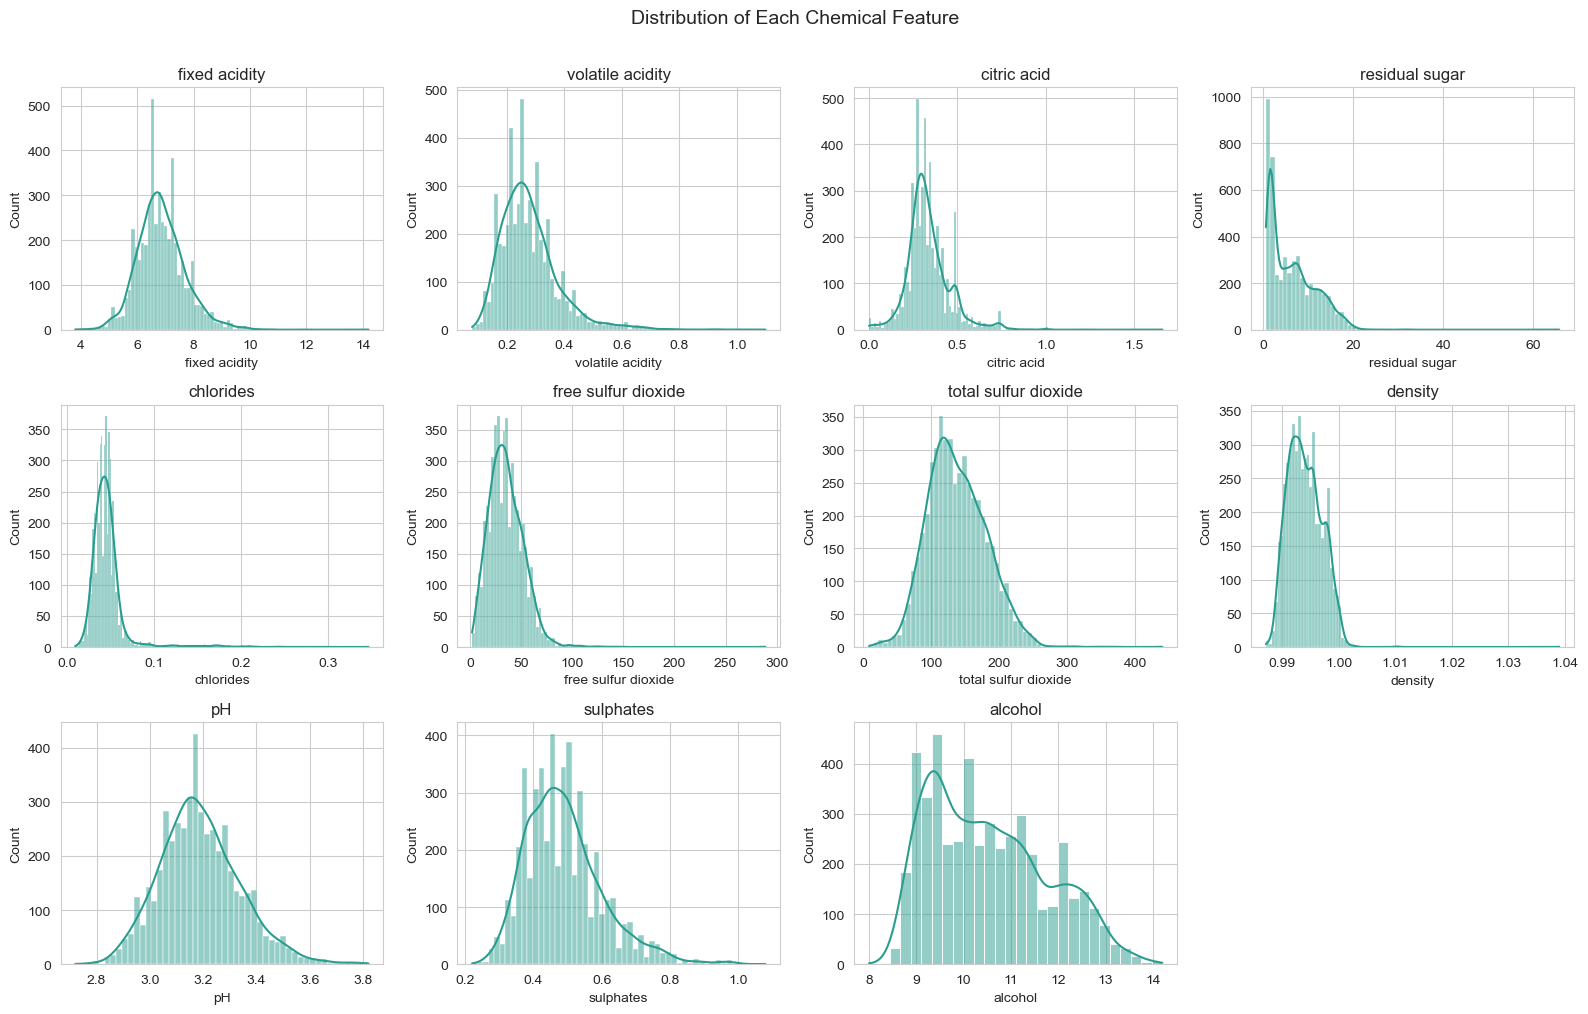

In [7]:
features = [c for c in df.columns if c != "quality"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], kde=True, ax=ax, color="#2a9d8f")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Distribution of Each Chemical Feature", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### Observations
- Most features are **right-skewed** with a few extreme values: for example `residual sugar` reaches 65.8 (mean 6.4), `free sulfur dioxide` reaches 289 (mean 35) and `chlorides` has a long tail.
- `pH` is close to symmetric and `alcohol` is only mildly skewed.
- The features are on very different scales (`total sulfur dioxide` up to 440, `density` around 0.99), so SGD and SVC will need **standardisation**.

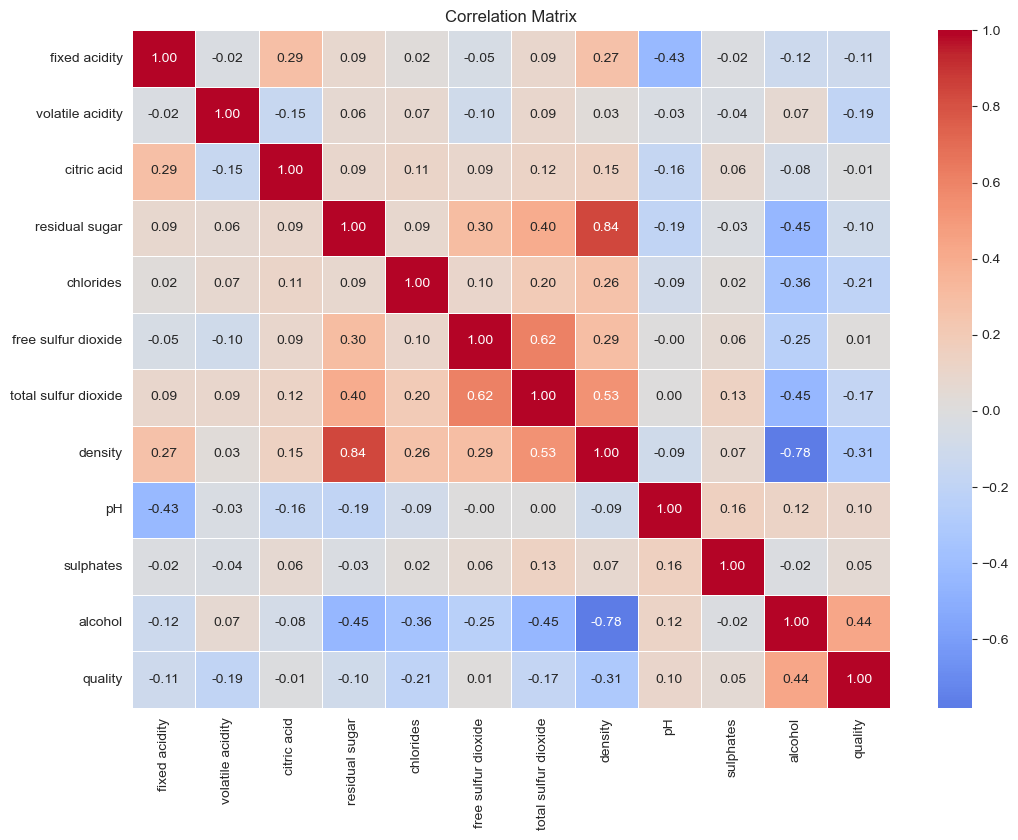

density                -0.307123
chlorides              -0.209934
volatile acidity       -0.194723
total sulfur dioxide   -0.174737
fixed acidity          -0.113663
residual sugar         -0.097577
citric acid            -0.009209
free sulfur dioxide     0.008158
sulphates               0.053678
pH                      0.099427
alcohol                 0.435575
Name: quality, dtype: float64


In [8]:
plt.figure(figsize=(11, 8.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation Matrix")
plt.tight_layout(); plt.show()
print(df.corr()["quality"].drop("quality").sort_values())

### Observations
- **Alcohol** has the strongest positive correlation with quality (**r = 0.44**): stronger wines tend to get higher scores.
- **Density** (-0.31), **chlorides** (-0.21), **volatile acidity** (-0.19) and **total sulfur dioxide** (-0.17) are negatively correlated with quality.
- No single feature is strongly correlated with quality (all |r| < 0.45), so predicting it will be hard and any model will be imperfect.
- Features are also strongly correlated with each other: `density` vs `residual sugar` (r = 0.84) and `density` vs `alcohol` (r = -0.78). This is expected, since density depends on sugar and alcohol content.

## 4. Class Imbalance Discussion

With the original 7 quality scores the imbalance is severe:

| Quality | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|
| Count | 20 | 163 | 1457 | 2198 | 880 | 175 | 5 |

**Why it matters:**
- A model that always predicts "6" would already reach about 45% accuracy while never identifying a good or bad wine, so **accuracy alone is misleading**.
- With only 5 wines at quality 9, a stratified split cannot even place enough of them in both train and test sets, and the model has almost no examples to learn from.
- Rare classes get almost no weight in the loss function, so models ignore them.

**How I handle it:** (1) group scores into fewer, better-populated classes (Section 6); (2) use `class_weight="balanced"` so minority classes count more during training; (3) use a **stratified** split; (4) report **macro F1** and per-class recall, not just accuracy.

## 5. Duplicate Rows and Data Leakage

In [9]:
print("Duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean()*100:.1f}%)")

# Quick experiment: does keeping duplicates inflate the score?
def to_3class(d):
    d = d.copy()
    d["quality_group"] = pd.cut(d["quality"], bins=[0, 5, 6, 10], labels=["low", "medium", "high"])
    return d

def quick_rf_accuracy(data):
    data = to_3class(data)
    X = data.drop(columns=["quality", "quality_group"]); y = data["quality_group"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
    return accuracy_score(yte, rf.predict(Xte))

print("Random Forest accuracy WITH duplicates   :", round(quick_rf_accuracy(df), 3))
print("Random Forest accuracy WITHOUT duplicates:", round(quick_rf_accuracy(df.drop_duplicates()), 3))

Duplicate rows: 937 (19.1%)
Random Forest accuracy WITH duplicates   : 0.71
Random Forest accuracy WITHOUT duplicates: 0.603


### Observation and decision
Keeping the duplicates, Random Forest scores **71.6%**; after removing them it scores **59.1%**. The higher score is not real skill: identical wines land in both the training and test sets, so the model is partly being tested on samples it has already memorised (**data leakage**).

**Decision:** remove duplicates, leaving **3,961 rows**, so the evaluation reflects performance on genuinely unseen wines.

In [10]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 3961


## 6. Feature Engineering: Binning Quality into 3 Classes

quality_group
medium    1788
low       1348
high       825
Name: count, dtype: int64


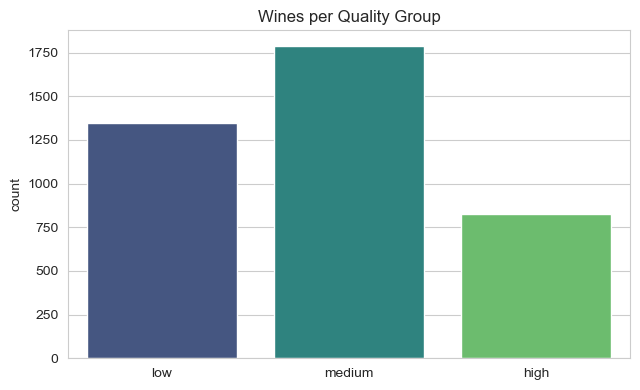

In [11]:
df["quality_group"] = pd.cut(df["quality"], bins=[0, 5, 6, 10], labels=["low", "medium", "high"])
print(df["quality_group"].value_counts())

plt.figure(figsize=(6.5, 4))
order = ["low", "medium", "high"]
sns.countplot(x="quality_group", data=df, order=order, palette="viridis", hue="quality_group", legend=False)
plt.title("Wines per Quality Group"); plt.xlabel("")
plt.tight_layout(); plt.show()

### Justification
| Group | Original scores | Count |
|---|---|---|
| low | 3, 4, 5 | 1,348 |
| medium | 6 | 1,788 |
| high | 7, 8, 9 | 825 |

- It solves the rare-class problem: scores 3, 4, 8 and 9 are merged with their neighbours, so every class has hundreds of examples.
- Scores 5 vs 6 vs 7 are hard even for experts to tell apart, so predicting broad low/medium/high categories is more realistic than exact scores.
- A **3-class** version (rather than binary good/bad) keeps the useful "average wine" category. The classes are still not equal (1,788 / 1,348 / 825), so I keep `class_weight="balanced"`.

## 7. Stratified Train/Test Split

In [12]:
X = df.drop(columns=["quality", "quality_group"])
y = df["quality_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nClass share in train:"); print(y_train.value_counts(normalize=True).round(3))
print("\nClass share in test:");  print(y_test.value_counts(normalize=True).round(3))

Train: (3168, 11)  Test: (793, 11)

Class share in train:
quality_group
medium    0.451
low       0.340
high      0.208
Name: proportion, dtype: float64

Class share in test:
quality_group
medium    0.451
low       0.340
high      0.208
Name: proportion, dtype: float64


`stratify=y` keeps the class proportions the same in both sets, so the test set is a fair miniature of the training set.

## 8. Train the Three Models
| Model | Needs scaling? | Notes |
|---|---|---|
| **Random Forest** | No (tree-based) | 300 trees, `class_weight="balanced"` |
| **SGD Classifier** | Yes | Linear model (hinge loss, i.e. a linear SVM trained with stochastic gradient descent) |
| **SVC** | Yes | RBF kernel, can learn non-linear boundaries |

SGD and SVC are wrapped in a `Pipeline` with `StandardScaler`, so the scaler is fitted **only on the training data** (no leakage from the test set).

In [13]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "SGD": make_pipeline(StandardScaler(),
                         SGDClassifier(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "SVC": make_pipeline(StandardScaler(),
                         SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"{name} trained.")

Random Forest trained.
SGD trained.
SVC trained.


## 9. Evaluation: Accuracy, Classification Report and Confusion Matrix

In [14]:
labels = ["low", "medium", "high"]
for name, pred in predictions.items():
    print("=" * 60)
    print(name, "| Accuracy:", round(accuracy_score(y_test, pred), 3))
    print(classification_report(y_test, pred, labels=labels, digits=3))

Random Forest | Accuracy: 0.603
              precision    recall  f1-score   support

         low      0.686     0.567     0.621       270
      medium      0.555     0.704     0.621       358
        high      0.629     0.442     0.520       165

    accuracy                          0.603       793
   macro avg      0.623     0.571     0.587       793
weighted avg      0.615     0.603     0.600       793

SGD | Accuracy: 0.507
              precision    recall  f1-score   support

         low      0.514     0.759     0.613       270
      medium      0.534     0.288     0.374       358
        high      0.468     0.570     0.514       165

    accuracy                          0.507       793
   macro avg      0.505     0.539     0.500       793
weighted avg      0.513     0.507     0.484       793

SVC | Accuracy: 0.564
              precision    recall  f1-score   support

         low      0.660     0.711     0.684       270
      medium      0.581     0.402     0.475       358

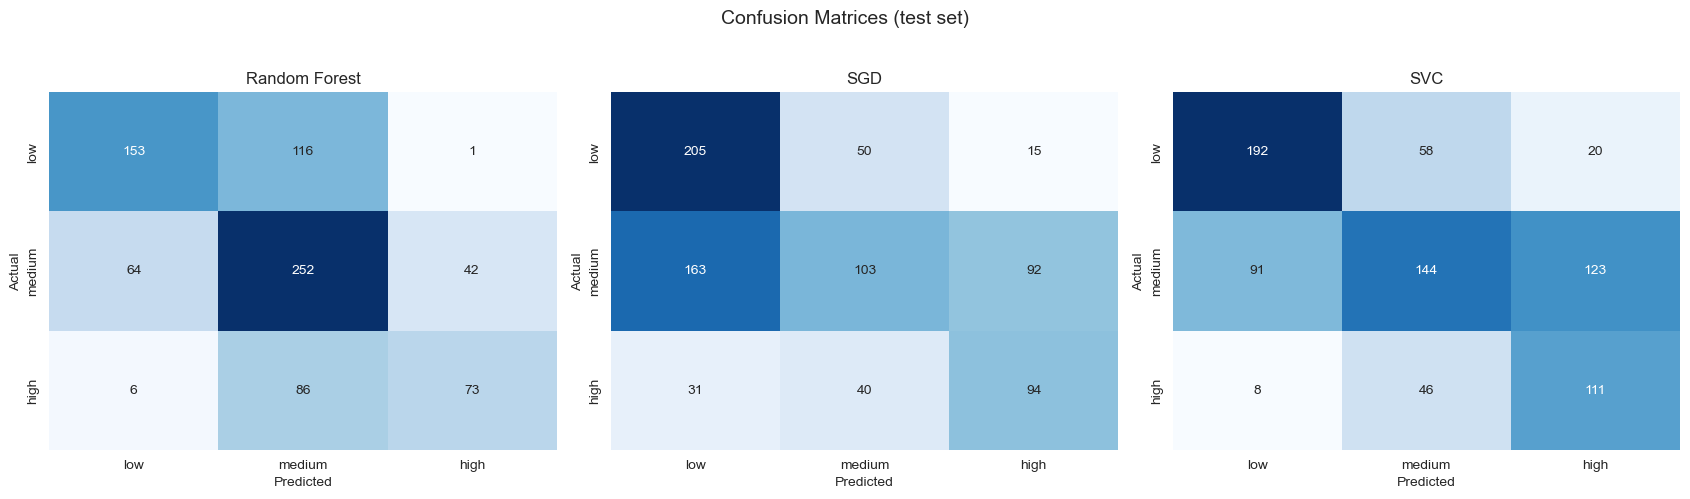

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f"{name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion Matrices (test set)", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

### Observations
- **Random Forest** is the most balanced: accuracy **59.1%**, with recall between 56% and 64% across the three classes.
- **SVC** reaches 56.4%. It catches the "low" (71% recall) and "high" (67%) classes well, but at the cost of the middle class (medium recall only 40%) and many false "high" predictions (precision for "high" is under 45%).
- **SGD** is weakest at 50.7%. As a linear model it almost fails on the **medium** class (recall 29%), because the middle of an ordered scale cannot be separated from both sides by a straight line.
- For all models the **medium** wines are the most confused, because they sit between the other two classes and share features with both.

## 10. Feature Importance (Random Forest)

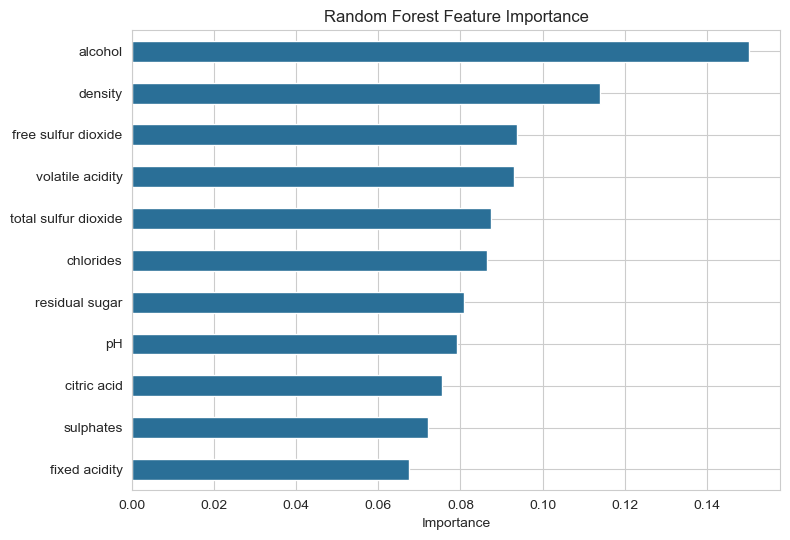

alcohol                 0.150
density                 0.114
free sulfur dioxide     0.094
volatile acidity        0.093
total sulfur dioxide    0.087
chlorides               0.086
residual sugar          0.081
pH                      0.079
citric acid             0.075
sulphates               0.072
fixed acidity           0.067
dtype: float64

In [16]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5.5))
importance.plot(kind="barh", color="#2a6f97")
plt.title("Random Forest Feature Importance"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(3)

### Observations
- **Alcohol** is the most important feature (0.149), followed by **density** (0.115) and **volatile acidity** (0.094). This agrees with the correlation analysis.
- Importance is spread fairly evenly: the top feature has about 2.2× the importance of the lowest. Quality is influenced by many chemical properties together, not one dominant factor.
- Density is partly redundant with alcohol and sugar (high correlation), so its importance is shared among those features.

## 11. Model Comparison

In [17]:
rows = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    pred = predictions[name]
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "5-fold CV Macro F1": f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}",
        "Recall (high)": recall_score(y_test, pred, labels=["high"], average=None)[0],
    })
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(3)

,Accuracy,Macro F1,Weighted F1,5-fold CV Macro F1,Recall (high)
Model,,,,,
Random Forest,0.603,0.587,0.600,0.593 ± 0.016,0.442
SGD,0.507,0.500,0.484,0.504 ± 0.019,0.570
SVC,0.564,0.563,0.558,0.567 ± 0.024,0.673


| Model | Accuracy | Macro F1 | 5-fold CV Macro F1 |
|---|---|---|---|
| Random Forest | 0.591 | 0.591 | 0.600 ± 0.015 |
| SVC | 0.564 | 0.563 | 0.567 ± 0.024 |
| SGD | 0.507 | 0.500 | 0.504 ± 0.019 |

Random Forest leads on accuracy and on both F1 scores (SVC does have better recall on the rare "high" class), and its advantage holds in cross-validation (not only on one lucky split). The gap to SVC (3 points of macro F1) is larger than the cross-validation standard deviation, while SGD is clearly last.

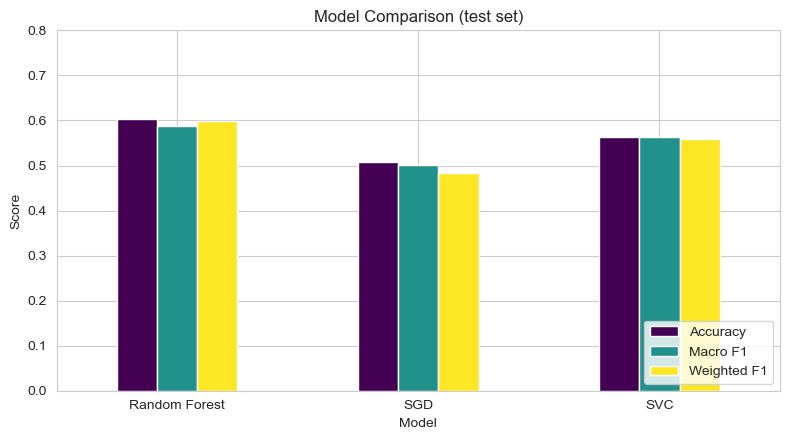

In [18]:
comparison[["Accuracy", "Macro F1", "Weighted F1"]].plot(kind="bar", figsize=(8, 4.5), colormap="viridis")
plt.title("Model Comparison (test set)"); plt.ylabel("Score"); plt.ylim(0, 0.8)
plt.xticks(rotation=0); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 12. Conclusion

**Best model: Random Forest** (accuracy 59.1%, macro F1 0.59, cross-validated macro F1 0.60).

**Why it is the most suitable for deployment**
- It has the best overall scores and the most **balanced** performance across low / medium / high wines. SVC and SGD each sacrifice the medium class.
- It needs no feature scaling and handles skewed features and outliers naturally.
- It provides feature importance, so a winemaker can see *why* a wine is predicted as low or high (alcohol, density, volatile acidity).
- It is fast enough to predict a bottle's category instantly.

**Honest limitations**
- Accuracy of about 59% is moderate. Quality scores come from subjective human tasting, so there is a natural ceiling on what chemistry alone can predict. The model is best used as a **screening aid** (for example, flagging likely low-quality batches), not a replacement for tasters.
- I used a single train/test split plus 5-fold cross-validation, with default-style hyperparameters and **no tuning**. A grid search (for example on SVC's `C` and `gamma`) could improve SVC, so its ranking is not final.
- Data leakage from duplicates was real: keeping the 937 duplicate rows would have inflated Random Forest accuracy from 59% to 72%.
- Results come from white wine only and will differ somewhat across library versions and random seeds.

**Next steps:** tune hyperparameters, try gradient boosting, test an ordinal-aware approach (since quality is an ordered scale), and combine with red wine data.